# Assignment 1 — South German Credit
Data Science for Business · 2026–2027

Student 1: Athulya Mohandas Menon - r1070436  
Student 2: name and r-number

Complete this notebook in Python. Keep your code and relevant outputs here; write the report in `A1_Template.docx`. The full instructions are in `A1_Assignment.pdf`.

In Colab: upload this `.ipynb` to Drive, open it with **Google Colaboratory**, then click **Connect**. Upload `South_German_Credit.csv` through **Files**. Locally, keep the CSV in the working folder or update `DATA_PATH`.


## 0. Load the dataset
Run the two cells below, then start Question 1.


In [1]:
from pathlib import Path
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# imports for the analysis
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

SEED = 2026                                                   

In [2]:
DATA_PATH = Path("South_German_Credit.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Upload South_German_Credit.csv to the Colab Files panel, "
        "or set DATA_PATH to the CSV location on your computer."
    )

credit = pd.read_csv(DATA_PATH)
display(credit.head())

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


## 1. Explore the data
Follow Question 1 on page 3: check the data, create the target (1 = bad, 0 = good) and make the required stratified 70/30 split before exploring relationships.

Choose two variables and compare their joint groups in one figure. Put your choices, figure and interpretation in report Part 1. Keep checks and supporting calculations here.


### 1.1–1.2 Data checks, modelling target and the 70/30 split
The test sample is created here and **not touched** until the final evaluation (Question 2.3 and Question 3).

In [3]:
cat_labels = {
 "status": {1: "no checking account", 2: "balance < 0 DM", 3: "0–200 DM", 4: "≥ 200 DM / salary"},
 "credit_history": {0: "past payment delays", 1: "critical / credits elsewhere", 2: "no credits / all repaid", 3: "existing credits paid duly", 4: "all credits here repaid"},
 "purpose": {0: "other", 1: "new car", 2: "used car", 3: "furniture/equipment", 4: "radio/TV", 5: "domestic appliances", 6: "repairs", 7: "education", 8: "vacation", 9: "retraining", 10: "business"},
 "savings": {1: "unknown / none", 2: "< 100 DM", 3: "100–500 DM", 4: "500–1,000 DM", 5: "≥ 1,000 DM"},
 "employment_duration": {1: "unemployed", 2: "< 1 year", 3: "1–4 years", 4: "4–7 years", 5: "≥ 7 years"},
 "installment_rate": {1: "≥ 35% of income", 2: "25–35%", 3: "20–25%", 4: "< 20%"},
 "personal_status_sex": {1: "male, divorced/separated", 2: "female non-single / male single", 3: "male, married/widowed", 4: "female, single"},
 "other_debtors": {1: "none", 2: "co-applicant", 3: "guarantor"},
 "present_residence": {1: "< 1 year", 2: "1–4 years", 3: "4–7 years", 4: "≥ 7 years"},
 "property": {1: "unknown / none", 2: "car or other", 3: "savings agr. / life insurance", 4: "real estate"},
 "other_installment_plans": {1: "bank", 2: "stores", 3: "none"},
 "housing": {1: "free", 2: "rent", 3: "own"},
 "number_credits": {1: "1", 2: "2–3", 3: "4–5", 4: "≥ 6"},
 "job": {1: "unemployed / unskilled non-res.", 2: "unskilled resident", 3: "skilled employee", 4: "manager / self-employed"},
 "people_liable": {1: "3 or more", 2: "0 to 2"},
 "telephone": {1: "no", 2: "yes"},
 "foreign_worker": {1: "yes", 2: "no"}
}
num = ["duration", "amount", "age"]
cat = list(cat_labels)
var = num + cat
units = {"duration": "months", "age": "years", "amount": ""}
readable = {"status": "checking account", "credit_history": "credit history", "employment_duration": "employment duration",
        "installment_rate": "instalment rate", "personal_status_sex": "personal status/sex", "other_debtors": "other debtors",
        "present_residence": "residence duration", "other_installment_plans": "other instalment plans", "number_credits": "number of credits",
        "people_liable": "dependants", "foreign_worker": "foreign worker", "duration": "credit duration", "amount": "credit amount"}
nice = lambda v: readable.get(v, v.replace("_", " "))
ordinal = {"employment_duration", "installment_rate", "present_residence", "number_credits", "job"}   
# exclude to prevent sexism/racism biases? standard practice in insurance/finance?
exclude = {"personal_status_sex": "contains sex", "foreign_worker": "nationality"}

n_dup, n_missing = int(credit.duplicated().sum()), int(credit.isna().sum().sum())
print(f"Dimensions: {credit.shape[0]} rows x {credit.shape[1]} columns")
print("Variable types:", credit.dtypes.astype(str).value_counts().to_dict(), "numeric;  17 categorical variables are category codes")
print("Missing values:", n_missing, "| duplicate rows:", n_dup)
print("credit_risk counts (0 = bad, 1 = good):", credit["credit_risk"].value_counts().sort_index().to_dict())
display(credit[num].describe().T[["min", "25%", "50%", "75%", "max"]])

data = credit.copy()
data["bad"] = 1 - data["credit_risk"]

#  stratified 70/30 split 
train, test = train_test_split(data, test_size=0.30, random_state=SEED, stratify=data["bad"])
print(f"\n random_state={SEED}: train {len(train)} rows ({train['bad'].sum()} bad, {train['bad'].mean():.1%}), "f"test {len(test)} rows ({test['bad'].sum()} bad, {test['bad'].mean():.1%})")

Dimensions: 1000 rows x 21 columns
Variable types: {'int64': 21} numeric;  17 categorical variables are category codes
Missing values: 0 | duplicate rows: 0
credit_risk counts (0 = bad, 1 = good): {0: 300, 1: 700}


,min,25%,50%,75%,max
duration,4.0,12.0,18.0,24.00,72.0
amount,250.0,1365.5,2319.5,3972.25,18424.0
age,19.0,27.0,33.0,42.00,75.0



 random_state=2026: train 700 rows (210 bad, 30.0%), test 300 rows (90 bad, 30.0%)


### Preprocessing, WOE and Binning

1. creates a temporary df linking each observation's assigned bin (level) with its target outcome (0 or 1)
2. groups the data by bin level and aggregates two metrics: total observations in the bin (n) and total bad credits (bad)
3. calculates the number of good credits per bin by subtracting bads from the total count
4. stores total number of bins (k), total good credits across the entire dataset (G), and total bad credits across the entire dataset (B)
5. calculates the prop of goods/bads in each bin via Laplace smoothing (adding smooth to num and smooth * k to denom) to handle zero-count bins safely
6. computes the Weight of Evidence for each bin as the natural logarithm of the ratio of good distribution to bad distribution
7. computes the Information Value contribution for each individual bin and returns the summary df
8. translates a numerical IV score into a qualitative risk category (IV of 0.35 = strong)
9. create a function that fits a variable, converts inputs to Pandas Series, and checks whether the variable is quantitative or categorical
10. Quantitative - create cutoffs from quantiles. If whole number, it floors/rounds them and filters out edges outside the variable's min/max bounds
11. monotonicity enabled - tests if WoE values move steadily up or down across bins. If not, it removes that edge until monotonic trend is achieved
12. finalizes bin categories or switches to Categorical Branch, mapping codes using the global cat_labels dictionary and handling missing entries
13. internal helper function helps map any array into the exact categories or bins learned during training
14. computes a WoE table to find bin whose WoE is closest to 0 - fallback for unseen categories later
15. calculate final metrics and returns a Model Dictionary containing everything needed to transform future datasets consistently
16. takes new data and a saved model dictionary, applies the training edges and maps the bins to their learned WoE values
17. initializes a storage dictionary and loops through every variable fitting the binner on the training data and storing each model state
18. converts records into a df, sorts features from highest IV to lowest, resets the row index, and formats with a blue gradient heatmap

In [4]:
def woe_table(levels, y, smooth=0.5):
    d = pd.DataFrame({"level": pd.Categorical(levels), "bad": np.asarray(y, dtype=int)})
    g = d.groupby("level", observed=False)["bad"].agg(n="size", bad="sum")
    g["good"] = g["n"] - g["bad"]
    k, G, B = len(g), g["good"].sum(), g["bad"].sum()
    g["dist_good"] = (g["good"] + smooth) / (G + smooth * k)
    g["dist_bad"] = (g["bad"] + smooth) / (B + smooth * k)
    g["woe"] = np.log(g["dist_good"] / g["dist_bad"])
    g["iv_part"] = (g["dist_good"] - g["dist_bad"]) * g["woe"]
    g["bad_rate"] = g["bad"] / g["n"].replace(0, np.nan)
    return g

def iv_strength(iv):
    return "not useful" if iv < 0.02 else "weak" if iv < 0.1 else "medium" if iv < 0.3 else "strong" if iv < 0.5 else "very strong"

def wilson(k, n, z=1.96):
    p = k/n
    d = 1+z*z/n
    c = p+z*z/(2*n)
    a = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))
    return (c-a)/d,(c+a)/d

def quant_labels(var, edges, integer):
    u = f" {units[var]}" if units.get(var) else ""
    f = (lambda v: f"{v:,.0f}") if integer else (lambda v: f"{v:,.2f}")
    e = list(edges)
    if not e: 
        return ["all"]
    labs = [f"≤ {f(e[0])}{u}"]
    for a, b in zip(e[:-1], e[1:]):
        labs.append(f"{f(a + 1)}–{f(b)}{u}" if integer else f"({f(a)}, {f(b)}]{u}")
    return labs + [f"> {f(e[-1])}{u}"]

def auto_edges(x, y, max_bins=4, min_frac=0.05, start=10, monotone=True):
    x = np.asarray(x, float)
    y = np.asarray(y)
    cand = np.unique(np.quantile(x, np.linspace(0, 1, start + 1)[1:-1]))
    if np.allclose(x, np.round(x)): cand = np.unique(np.floor(cand))
    edges = np.array([e for e in cand if x.min() < e < x.max()])
    
    tab = lambda e: (lambda t: (t["n"].to_numpy(), t["woe"].to_numpy()))(woe_table(pd.cut(x, [-np.inf, *e, np.inf]), y))
    
    if monotone and len(edges) > 1:
        w0 = tab(edges)[1]
        up = np.corrcoef(np.arange(len(w0)), w0)[0, 1] >= 0
        while len(edges) > 1:
            w = tab(edges)[1]
            viol = np.where((np.diff(w) if up else -np.diff(w)) < 0)[0]
            if len(viol) == 0: break
            edges = np.delete(edges, viol[0])
            
    while len(edges) > 1:
        n, w = tab(edges)
        small = (n / len(x)).min() < min_frac
        if len(n) <= max_bins and not small: break
        if small:
            s_ = int(n.argmin())
            cands = [j for j in (s_ - 1, s_) if 0 <= j < len(edges)]
            drop = min(cands, key=lambda j: abs(w[j] - w[j + 1]))
        else: drop = int(np.argmin(np.abs(np.diff(w))))
        edges = np.delete(edges, drop)
        
    return [float(e) for e in edges]

def group_label(var, codes):
    names = [cat_labels[var][c] for c in sorted(codes)]
    return " + ".join(names) if len(names) <= 2 else f"{names[0]} + {names[1]} + {len(names) - 2} more"

def merge_levels(x, y, var, ordinal, min_frac, manual=None):
    if manual:
        mp = {c: name for name, cs in manual.items() for c in cs}
        return {c: mp.get(c, cat_labels[var][c]) for c in sorted(x.unique())}
    groups = [[c] for c in sorted(x.unique())]
    while len(groups) > 2:
        st = [(int(x.isin(g).sum()), int(y[x.isin(g)].sum())) for g in groups]
        ns = np.array([s[0] for s in st])
        if ns.min() / len(x) >= min_frac: 
            break
        G, B, k = sum(n - b for n, b in st), sum(b for n, b in st), len(groups)
        woe = np.array([np.log(((n - b + .5) / (G + .5 * k)) / ((b + .5) / (B + .5 * k))) for n, b in st])
        s = int(ns.argmin())
        cands = [j for j in (s - 1, s + 1) if 0 <= j < len(groups)] if ordinal else [j for j in range(len(groups)) if j != s]
        j = min(cands, key=lambda j: abs(woe[s] - woe[j]))
        lo, hi = sorted((s, j))
        groups[lo] = groups[lo] + groups[hi]
        del groups[hi]
    return {c: group_label(var, g) for g in groups for c in g}


def get_bin_levels(x, kind, edges, order, cat_map, neutral):
    x_ser = pd.Series(np.asarray(x))
    if kind == "quant": return pd.Categorical(pd.cut(x_ser, [-np.inf, *edges, np.inf], labels=order))
    else:
        lab = x_ser.map(cat_map)
        if lab.isna().sum() > 0 and neutral is not None: lab = lab.fillna(neutral)
        return pd.Categorical(lab, categories=order)

def fit_binner(var, x, y, max_bins=4, min_frac=0.05, manual=None, monotone=True):
    x_s, y_s = pd.Series(np.asarray(x)), pd.Series(np.asarray(y))
    kind = "quant" if var in num else "cat"
    
    if kind == "quant":
        integer = bool(np.allclose(x_s, np.round(x_s)))
        edges = list(manual) if manual is not None else auto_edges(x_s, y_s, max_bins, min_frac, monotone=monotone)
        order = quant_labels(var, edges, integer)
        cat_map, neutral = None, None
        lvls = get_bin_levels(x_s, kind, edges, order, cat_map, neutral)
    else:
        cat_map = merge_levels(x_s, y_s, var, var in ordinal, min_frac, manual)
        order = list(dict.fromkeys(cat_map[c] for c in sorted(cat_map)))
        edges = None
        temp_lab = x_s.map(cat_map)
        temp_neutral = temp_lab.dropna().iloc[0] if len(temp_lab.dropna()) > 0 else "unknown"
        lvls = pd.Categorical(temp_lab.fillna(temp_neutral), categories=order)

    table = woe_table(lvls, y_s)
    woe_map = table["woe"].to_dict()
    iv = float(table["iv_part"].sum())
    neutral = min(woe_map, key=lambda l: abs(woe_map[l]))

    if kind == "cat":
        lvls = get_bin_levels(x_s, kind, edges, order, cat_map, neutral)
        table = woe_table(lvls, y_s)
        woe_map = table["woe"].to_dict()
        iv = float(table["iv_part"].sum())
        neutral = min(woe_map, key=lambda l: abs(woe_map[l]))

    return {
        "var": var, "kind": kind, "edges": edges, "order": order,
        "map": cat_map, "neutral": neutral, "table": table, 
        "woe_map": woe_map, "iv": iv
    }

def transform_woe(x, model):
    x_ser = pd.Series(np.asarray(x))
    lvls = get_bin_levels(x_ser, model["kind"], model["edges"], model["order"], model["map"], model["neutral"])
    idx = x.index if hasattr(x, "index") else None
    return pd.Series(pd.Series(lvls).map(model["woe_map"]).astype(float).to_numpy(), index=idx)

make_binner = lambda v, **kw: fit_binner(v, train[v], train["bad"], **kw) # Note: typically called dynamically in loops

rows = []
for v in var:
    model = fit_binner(v, train[v], train["bad"])
    rows.append({
        "Predictor": v, 
        "Type": "Quantitative" if v in num else "Categorical", 
        "Levels": len(model["order"]),
        "IV": model["iv"], 
        "Strength": iv_strength(model["iv"]), 
        "Excluded": exclude.get(v, "")
    })

screen = pd.DataFrame(rows).sort_values("IV", ascending=False).reset_index(drop=True)
display(screen.style.format({"IV": "{:.3f}"}).background_gradient(subset=["IV"], cmap="Blues").hide(axis="index"))


Predictor,Type,Levels,IV,Strength,Excluded
status,Categorical,4,0.559,very strong,
savings,Categorical,5,0.300,strong,
duration,Quantitative,4,0.298,medium,
purpose,Categorical,6,0.238,medium,
credit_history,Categorical,4,0.233,medium,
property,Categorical,4,0.101,medium,
amount,Quantitative,4,0.100,medium,
age,Quantitative,4,0.098,weak,
employment_duration,Categorical,5,0.092,weak,
housing,Categorical,3,0.072,weak,


### groups of two variables and the figure for report 

In [5]:
usable = screen[screen["Excluded"] == ""]
cat_var = usable[usable["Type"] == "Categorical"]["Predictor"].iloc[0]
q_var = usable[usable["Type"] == "Quantitative"]["Predictor"].iloc[0]

iv_of = lambda v: float(screen.loc[screen["Predictor"] == v, "IV"].iloc[0])
print(f"Chosen: {cat_var} (IV {iv_of(cat_var):.2f}) and {q_var} (IV {iv_of(q_var):.2f})")

bc_model = fit_binner(cat_var, train[cat_var], train["bad"], min_frac=0.10)
bq_model = fit_binner(q_var, train[q_var], train["bad"], max_bins=3, min_frac=0.15)

def get_levels(x, model):
    x_s = pd.Series(np.asarray(x))
    if model["kind"] == "quant":
        return pd.Categorical(pd.cut(x_s, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    return pd.Categorical(x_s.map(model["map"]).fillna(model["neutral"]), categories=model["order"])

def joint_table(cat_levels, q_levels, y):
    d = pd.DataFrame({"cat": cat_levels, "q": q_levels, "bad": np.asarray(y)})
    g = d.groupby(["cat", "q"], observed=True)["bad"].agg(n="size", bad="sum")
    g["rate"] = g["bad"] / g["n"]
    ci = np.array([wilson(k, n) for k, n in zip(g["bad"], g["n"])])
    g["lo"], g["hi"] = ci[:, 0], ci[:, 1]
    return g

g = joint_table(get_levels(train[cat_var], bc_model), get_levels(train[q_var], bq_model), train["bad"])
overall, B_train = float(train["bad"].mean()), int(train["bad"].sum())

show = g.copy()
show["share of all bad"] = show["bad"] / B_train
display(show.style.format("{:.1%}", subset=["rate", "lo", "hi", "share of all bad"]) if hasattr(show.style, "format") else show)

top_rate, top_count = g["rate"].idxmax(), g["bad"].idxmax()
reliable = g[g["n"] >= 30]
print(f"\nHighest rate: {top_rate} (Rate: {g.loc[top_rate,'rate']:.1%}, n={g.loc[top_rate,'n']}, 95% CI: {g.loc[top_rate,'lo']:.1%}-{g.loc[top_rate,'hi']:.1%})")
print(f"Most bad credits: {top_count} ({g.loc[top_count,'bad']} of {B_train} bad, Rate: {g.loc[top_count,'rate']:.1%})")

alt_edges = list(np.unique(np.floor(train[q_var].quantile([1 / 3, 2 / 3]).to_numpy())))
bq2_model = fit_binner(q_var, train[q_var], train["bad"], manual=alt_edges)
bc2_model = fit_binner(cat_var, train[cat_var], train["bad"], min_frac=0.05)
g2 = joint_table(get_levels(train[cat_var], bc2_model), get_levels(train[q_var], bq2_model), train["bad"])

print(f"Alternative grouping highest rate: {g2['rate'].idxmax()} ({g2['rate'].max():.1%}, n={g2.loc[g2['rate'].idxmax(),'n']})")

Chosen: status (IV 0.56) and duration (IV 0.30)



Highest rate: ('no checking account', '> 24 months') (Rate: 66.7%, n=45, 95% CI: 52.1%-78.6%)
Most bad credits: ('no checking account', '16–24 months') (35 of 210 bad, Rate: 52.2%)
Alternative grouping highest rate: ('no checking account', '> 24 months') (66.7%, n=45)


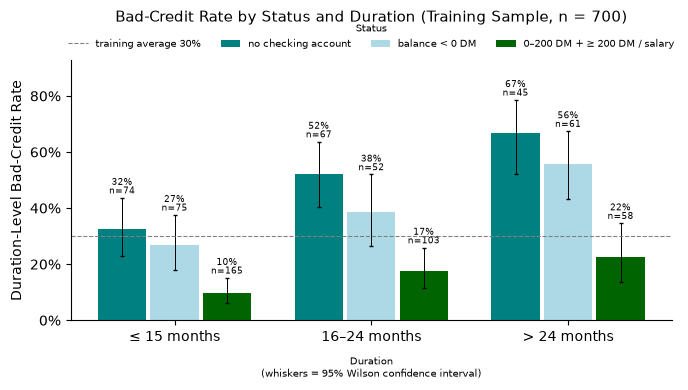

In [6]:
def plot_joint(g, cat_order, q_order, cat_name, q_name, overall, n_train, figsize=(7.2, 4.0)):
    clean_cat_name = cat_name.strip().title()
    clean_q_name = q_name.strip().title()

    colors = ["teal", "lightblue", "darkgreen", "orange"]
    fig, ax = plt.subplots(figsize=figsize)
    
    nc = len(cat_order)
    bar_width = 0.8 / nc  
    for i, cat in enumerate(cat_order):
        for j, q in enumerate(q_order):
            if (cat, q) not in g.index:
                continue
            
            row = g.loc[(cat, q)]
            x_pos = j + (i - (nc - 1) / 2) * bar_width
            ax.bar(x_pos, row["rate"], width=bar_width * 0.92, color=colors[i % len(colors)], linewidth=0.5, label=cat if j == 0 else "")
            ax.errorbar(x_pos, row["rate"],  yerr=[[row["rate"] - row["lo"]], [row["hi"] - row["rate"]]], color="black", lw=0.7, capsize=1.5)
            ax.text(x_pos, row["hi"] + 0.012, f"{row['rate']:.0%}\nn={int(row['n'])}", ha="center", va="bottom", fontsize=6.5, linespacing=0.95)

    ax.axhline(overall, color="gray", linestyle="--", linewidth=0.8, label=f"training average {overall:.0%}")
    ax.set_xticks(range(len(q_order)))
    ax.set_xticklabels([str(q) for q in q_order], fontsize=10)
    
    ax.set_ylim(0, min(1.0, g["hi"].max() + 0.14)) # Add padding for labels
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylabel(f"{clean_q_name}-Level Bad-Credit Rate", fontsize=10)
    
    ax.set_xlabel(f"{clean_q_name}\n(whiskers = 95% Wilson confidence interval)", fontsize=7, labelpad=8)
    ax.set_title(f"Bad-Credit Rate by {clean_cat_name} and {clean_q_name} (Training Sample, n = {n_train})", fontsize=11, fontweight="normal", pad=28)
    ax.legend(title=f"{clean_cat_name}", ncol=min(nc + 1, 4), fontsize=7, title_fontsize=7.5, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.01))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    
    return fig

overall_rate = float(train["bad"].mean())
fig1 = plot_joint(g=g, cat_order=bc_model["order"], q_order=bq_model["order"], cat_name=cat_var, q_name=q_var, overall=overall_rate, n_train=len(train))
plt.show()

In [7]:
data.groupby("status")["bad"].agg(n="size", bad_rate="mean")

,n,bad_rate
status,,
1,274,0.492701
2,269,0.390335
3,63,0.222222
4,394,0.116751


## 2. Build and evaluate the model
Follow Question 2 on page 4. Select predictors, including at least one quantitative variable, define their levels and apply WOE. Fit logistic regression using only those WOE predictors; calculate IV and compare training/test ROC curves and AUC.

Justify choices and interpret results in report Part 2. Keep calculations, WOE tables and model coefficients here.


### Predictor selection and level definitions

k,cv_auc,sd,se
1,0.693,0.035,0.015
2,0.733,0.037,0.016
3,0.759,0.035,0.016
4,0.761,0.036,0.016
5,0.779,0.036,0.016
6,0.768,0.047,0.021
7,0.770,0.049,0.022
8,0.767,0.046,0.021
9,0.770,0.043,0.019
10,0.775,0.037,0.017


Best CV AUC: 0.779 at k=5 (SE: 0.016)
Optimal k within tolerance: 5
Selected predictors: ['status', 'savings', 'duration', 'purpose', 'credit_history']


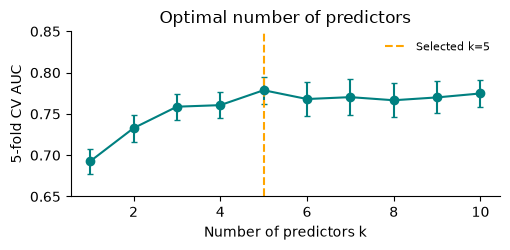

 • Smallest IV: 0.233
 • Strongest predictor association: duration & purpose (Cramer's V = 0.17)


In [9]:
def fit_lr(X, y):
    return LogisticRegression(C=np.inf, solver="lbfgs", max_iter=10000, tol=1e-10).fit(X, y)

CAND = [v for v in var if v not in exclude]
K_MAX, TOL, K_CAP = 10, 0.005, 8  
FINAL_OVERRIDE = None         

def transform_woe(x, model):
    x_ser = pd.Series(np.asarray(x))
    if model["kind"] == "quant": lvls = pd.Categorical(pd.cut(x_ser, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    else: lvls = pd.Categorical(x_ser.map(model["map"]).fillna(model["neutral"]), categories=model["order"])
    idx = x.index if hasattr(x, "index") else None
    return pd.Series(pd.Series(lvls).map(model["woe_map"]).astype(float).to_numpy(), index=idx)

def run_cv_k_curve(df, cand, k_max, n_splits=5, seed=SEED):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = {k: [] for k in range(1, k_max + 1)}
    
    for train_idx, val_idx in skf.split(df, df["bad"]):
        train_fold, val_fold = df.iloc[train_idx], df.iloc[val_idx]
        
        fold_fits = {v: fit_binner(v, train_fold[v], train_fold["bad"]) for v in cand}
        iv_ranked_vars = sorted(cand, key=lambda v: fold_fits[v]["iv"], reverse=True)
        
        xtrain_woe = pd.DataFrame({v: transform_woe(train_fold[v], fold_fits[v]) for v in cand})
        xval_woe = pd.DataFrame({v: transform_woe(val_fold[v], fold_fits[v]) for v in cand})
        
        for k in scores:
            selected_cols = iv_ranked_vars[:k]
            lr_model = fit_lr(xtrain_woe[selected_cols], train_fold["bad"])
            preds = lr_model.predict_proba(xval_woe[selected_cols])[:, 1]
            scores[k].append(roc_auc_score(val_fold["bad"], preds))
            
    cv_summary = pd.DataFrame({
        "k": list(scores),
        "cv_auc": [np.mean(vals) for vals in scores.values()],
        "sd": [np.std(vals, ddof=1) for vals in scores.values()]
    })
    cv_summary["se"] = cv_summary["sd"] / np.sqrt(n_splits)
    return cv_summary

cvk = run_cv_k_curve(train, CAND, K_MAX)

best_row = cvk.loc[cvk["cv_auc"].idxmax()]
k_star = int(cvk[cvk["cv_auc"] >= best_row["cv_auc"] - TOL]["k"].min())
k_1se = int(cvk[cvk["cv_auc"] >= best_row["cv_auc"] - best_row["se"]]["k"].min())
k_uncapped = k_star
k_star = min(k_star, K_CAP)

iv_rank = [v for v in screen["Predictor"] if v in CAND]
final_vars = list(FINAL_OVERRIDE) if FINAL_OVERRIDE else iv_rank[:k_star]

if not any(v in num for v in final_vars):
    first_quant = next(v for v in iv_rank if v in num)
    final_vars[-1] = first_quant

display(cvk.style.format({"cv_auc": "{:.3f}", "sd": "{:.3f}", "se": "{:.3f}"}).hide(axis="index") if hasattr(cvk.style, "hide") else cvk)

print(f"Best CV AUC: {best_row['cv_auc']:.3f} at k={int(best_row['k'])} (SE: {best_row['se']:.3f})")
print(f"Optimal k within tolerance: {k_uncapped}")
print("Selected predictors:", final_vars)

fig, ax = plt.subplots(figsize=(5.2, 2.6))
ax.errorbar(cvk["k"], cvk["cv_auc"], yerr=cvk["se"], marker="o", color='teal', capsize=2)
ax.axvline(k_star, color='orange', linestyle="--", label=f"Selected k={k_star}")
ax.set_ylim(0.65, 0.85)
ax.set_xlabel("Number of predictors k")
ax.set_ylabel("5-fold CV AUC")
ax.set_title("Optimal number of predictors")
ax.legend(frameon=False, fontsize=8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


fits_sel = {v: fit_binner(v, train[v], train["bad"]) for v in final_vars}
def cramers_v(a, b):
    ct = pd.crosstab(np.asarray(a), np.asarray(b))
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))) if min(ct.shape) > 1 else 0.0
    
def get_bin_levels_eval(x, model):
    x_ser = pd.Series(np.asarray(x))
    if model["kind"] == "quant": return pd.Categorical(pd.cut(x_ser, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    return pd.Categorical(x_ser.map(model["map"]).fillna(model["neutral"]), categories=model["order"])

pairs = [
    (a, b, cramers_v(get_bin_levels_eval(train[a], fits_sel[a]), get_bin_levels_eval(train[b], fits_sel[b])))
    for i, a in enumerate(final_vars)
    for b in final_vars[i + 1:]
]
max_pair = max(pairs, key=lambda t: t[2])
min_iv = min(f["iv"] for f in fits_sel.values())

print(f" • Smallest IV: {min_iv:.3f}")
print(f" • Strongest predictor association: {max_pair[0]} & {max_pair[1]} (Cramer's V = {max_pair[2]:.2f})")

In [10]:
models = {v: fit_binner(v, train[v], train["bad"]) for v in final_vars}

parts = []
for v in final_vars:
    t = models[v]["table"].reset_index()
    t.insert(0, "predictor", v)
    parts.append(t[["predictor", "level", "n", "bad", "bad_rate", "woe", "iv_part"]])

woe_tab = pd.concat(parts, ignore_index=True)
woe_tab["share"] = woe_tab["n"] / len(train)

display(woe_tab.style.format({"bad_rate": "{:.1%}", "woe": "{:+.3f}", "iv_part": "{:.4f}", "share": "{:.1%}"}).hide(axis="index") if hasattr(woe_tab.style, "hide") else woe_tab)

iv_rows = []
for v in final_vars:
    iv_val = models[v]["iv"]
    iv_rows.append({
        "predictor": v,
        "IV": iv_val,
        "levels": len(models[v]["order"]),
        "strength": iv_strength(iv_val)
    })

iv_tab = pd.DataFrame(iv_rows).sort_values("IV", ascending=False).reset_index(drop=True)

display(iv_tab.style.format({"IV": "{:.3f}"}).hide(axis="index") if hasattr(iv_tab.style, "hide") else iv_tab)

top_iv_var = iv_tab.loc[0, "predictor"]
top_iv_val = iv_tab.loc[0, "IV"]
top_strength = iv_tab.loc[0, "strength"]

print(f"Highest training IV: {top_iv_var} (IV = {top_iv_val:.3f}, {top_strength})")
print("WOE by level of the highest-IV predictor:")
display(models[top_iv_var]["table"][["n", "bad_rate", "woe"]].sort_values("woe", ascending=False))

for v in final_vars:
    m = models[v]
    if m["kind"] == "cat":
        merged = [lvl for lvl in m["order"] if " + " in lvl]
        if merged: 
            print(f"Merged levels in {v}: {merged}")

predictor,level,n,bad,bad_rate,woe,iv_part,share
status,no checking account,186,89,47.8%,-0.756,0.1694,26.6%
status,balance < 0 DM,188,74,39.4%,-0.412,0.0489,26.9%
status,0–200 DM,50,11,22.0%,+0.392,0.0102,7.1%
status,≥ 200 DM / salary,276,36,13.0%,+1.044,0.3304,39.4%
savings,unknown / none,416,157,37.7%,-0.341,0.0731,59.4%
savings,< 100 DM,78,25,32.1%,-0.100,0.0011,11.1%
savings,100–500 DM,40,6,15.0%,+0.829,0.0327,5.7%
savings,"500–1,000 DM",35,3,8.6%,+1.388,0.0687,5.0%
savings,"≥ 1,000 DM",131,19,14.5%,+0.912,0.1246,18.7%
duration,≤ 9 months,99,14,14.1%,+0.932,0.0983,14.1%


predictor,IV,levels,strength
status,0.559,4,very strong
savings,0.300,5,strong
duration,0.298,4,medium
purpose,0.238,6,medium
credit_history,0.233,4,medium


Highest training IV: status (IV = 0.559, very strong)
WOE by level of the highest-IV predictor:


,n,bad_rate,woe
level,,,
≥ 200 DM / salary,276,0.130435,1.043515
0–200 DM,50,0.220000,0.392061
balance < 0 DM,188,0.393617,-0.412117
no checking account,186,0.478495,-0.756279


Merged levels in purpose: ['furniture/equipment + vacation', 'radio/TV + domestic appliances + 2 more']
Merged levels in credit_history: ['past payment delays + critical / credits elsewhere']


### Model, coefficients and intercept

In [11]:
binners = {v: fit_binner(v, train[v], train["bad"]) for v in final_vars}

def transform_woe(x, model):
    x_ser = pd.Series(np.asarray(x))
    if model["kind"] == "quant": lvls = pd.Categorical(pd.cut(x_ser, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    else: lvls = pd.Categorical(x_ser.map(model["map"]).fillna(model["neutral"]), categories=model["order"])
    idx = x.index if hasattr(x, "index") else None
    return pd.Series(pd.Series(lvls).map(model["woe_map"]).astype(float).to_numpy(), index=idx)

X_train = pd.DataFrame({v: transform_woe(train[v], binners[v]) for v in final_vars})
y_train = train["bad"].to_numpy()

logit = fit_lr(X_train, y_train)
b0 = float(logit.intercept_[0])
coefs = pd.Series(logit.coef_[0], index=final_vars)

X_design = np.column_stack([np.ones(len(X_train)), X_train.to_numpy()])
p_fit = logit.predict_proba(X_train)[:, 1]

weights = p_fit * (1 - p_fit)
fisher_info = X_design.T @ (X_design * weights[:, None])
cov_matrix = np.linalg.inv(fisher_info)
standard_errors = np.sqrt(np.diag(cov_matrix))

estimates = np.r_[b0, coefs.to_numpy()]
z_scores = estimates / standard_errors
p_values = 2 * (1 - stats.norm.cdf(np.abs(z_scores)))

coef_tab = pd.DataFrame({
    "term": ["intercept"] + final_vars,
    "coefficient": estimates,
    "std. error": standard_errors,
    "z": z_scores,
    "p-value": p_values
})

display(coef_tab.style.format({"coefficient": "{:+.4f}", "std. error": "{:.4f}", "z": "{:.2f}", "p-value": "{:.4f}"}).hide(axis="index") if hasattr(coef_tab.style, "hide") else coef_tab)

print(" Coefficients are NEGATIVE because WoE = ln(good/bad) is higher for safer levels.")
print(f" • Model Intercept: {b0:.4f}")

term,coefficient,std. error,z,p-value
intercept,-0.8477,0.0975,-8.69,0.0000
status,-0.7718,0.1313,-5.88,0.0000
savings,-0.9158,0.1934,-4.73,0.0000
duration,-0.9921,0.1765,-5.62,0.0000
purpose,-0.8979,0.1989,-4.52,0.0000
credit_history,-0.7710,0.2016,-3.82,0.0001


 Coefficients are NEGATIVE because WoE = ln(good/bad) is higher for safer levels.
 • Model Intercept: -0.8477


### ROC curves and check for overfitting

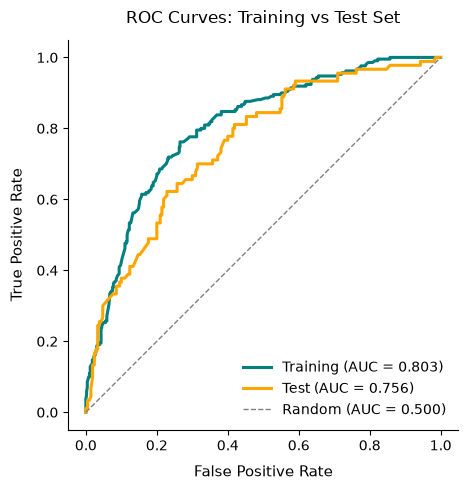

 • Train AUC: 0.803 | Test AUC: 0.756 (Bootstrap 95% CI: [0.697, 0.813])
 • Train-Test Gap: +0.048 | 5-fold CV Training AUC: 0.779
 • Gini Coefficients -> Train: 0.606, Test: 0.511
 • Test Sample Bads: 90 total
 • Bad rate in riskiest 30%: 53.3%
 • Bad rate in remaining 70%: 20.0%


In [13]:
binners = {v: fit_binner(v, train[v], train["bad"]) for v in final_vars}

def transform_woe(x, model):
    x_ser = pd.Series(np.asarray(x))
    if model["kind"] == "quant": lvls = pd.Categorical(pd.cut(x_ser, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    else: lvls = pd.Categorical(x_ser.map(model["map"]).fillna(model["neutral"]), categories=model["order"])
    idx = x.index if hasattr(x, "index") else None
    return pd.Series(pd.Series(lvls).map(model["woe_map"]).astype(float).to_numpy(), index=idx)

X_test = pd.DataFrame({v: transform_woe(test[v], binners[v]) for v in final_vars})
y_test = test["bad"].to_numpy()

for v in final_vars:
    model = binners[v]
    if model["kind"] == "cat":
        x_ser = pd.Series(np.asarray(test[v]))
        unseen_count = (~x_ser.isin(model["map"].keys())).sum()
    else: unseen_count = 0

p_tr = logit.predict_proba(X_train)[:, 1]
p_te = logit.predict_proba(X_test)[:, 1]

auc_tr = roc_auc_score(y_train, p_tr)
auc_te = roc_auc_score(y_test, p_te)

fig, ax = plt.subplots(figsize=(6.5, 5.0))
datasets = [(y_train, p_tr, "Training", 'teal'), (y_test, p_te, "Test", 'orange')]

for y_true, p_pred, name, color in datasets:
    fpr, tpr, _ = roc_curve(y_true, p_pred)
    score = roc_auc_score(y_true, p_pred)
    ax.plot(fpr, tpr, color=color, lw=2.2, label=f"{name} (AUC = {score:.3f})")

ax.plot([0, 1], [0, 1], color='grey', linestyle="--", linewidth=1.0, label="Random (AUC = 0.500)")

ax.set_xlabel("False Positive Rate", fontsize=11, labelpad=8)
ax.set_ylabel("True Positive Rate", fontsize=11, labelpad=8)
ax.set_title("ROC Curves: Training vs Test Set", fontsize=12, pad=12)

ax.legend(loc="lower right", fontsize=10, frameon=False)
ax.tick_params(labelsize=10)
ax.set_aspect("equal", adjustable="box")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

rng = np.random.default_rng(SEED)
bootstrap_aucs = []
n_test = len(y_test)

for _ in range(2000):
    sample_indices = rng.integers(0, n_test, n_test)
    y_sample = y_test[sample_indices]
    if 0 < y_sample.sum() < len(sample_indices):
        bootstrap_aucs.append(roc_auc_score(y_sample, p_te[sample_indices]))

ci_lo, ci_hi = np.percentile(bootstrap_aucs, [2.5, 97.5])

if "cvk" in locals() and len(final_vars) in set(cvk["k"]):  cv_auc_final = float(cvk.loc[cvk["k"] == len(final_vars), "cv_auc"].iloc[0])
else:  cv_auc_final = np.nan

train_test_gap = auc_tr - auc_te
gini_train = 2 * auc_tr - 1
gini_test = 2 * auc_te - 1

risk_threshold = np.quantile(p_te, 0.70)
is_risky = p_te >= risk_threshold
bad_rate_risky = y_test[is_risky].mean()
bad_rate_safe = y_test[~is_risky].mean()

print(f" • Train AUC: {auc_tr:.3f} | Test AUC: {auc_te:.3f} (Bootstrap 95% CI: [{ci_lo:.3f}, {ci_hi:.3f}])")
print(f" • Train-Test Gap: {train_test_gap:+.3f} | 5-fold CV Training AUC: {cv_auc_final:.3f}")
print(f" • Gini Coefficients -> Train: {gini_train:.3f}, Test: {gini_test:.3f}")
print(f" • Test Sample Bads: {int(y_test.sum())} total")
print(f" • Bad rate in riskiest 30%: {bad_rate_risky:.1%}")
print(f" • Bad rate in remaining 70%: {bad_rate_safe:.1%}")

## 3. Construct the scorecard
Follow Question 3 on page 5. Use 600 points at good:bad odds of 50:1 and 20 points to double those odds. Verify the scorecard against model probabilities on all test rows and check its scale.

Put the full scorecard and test-score boxplots in report Part 3, highlighting the two cases requested. Keep derivations and checks here.


### Scorecard construction and verification on the test sample

In [14]:
models = {v: fit_binner(v, train[v], train["bad"]) for v in final_vars}
coefs = pd.Series(logit.coef_[0], index=final_vars)

def nice_name(var_str):
    return var_str.replace("_", " ").title()

def get_bin_levels_eval(x, model):
    x_ser = pd.Series(np.asarray(x))
    if model["kind"] == "quant": return pd.Categorical(pd.cut(x_ser, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    return pd.Categorical(x_ser.map(model["map"]).fillna(model["neutral"]), categories=model["order"])

FACTOR = 20 / np.log(2)
OFFSET = 600 - FACTOR * np.log(50)
base = (OFFSET - FACTOR * b0) / len(final_vars)
print(f"Factor = PDO/ln2 = {FACTOR:.4f}; Offset = 600 - Factor*ln(50) = {OFFSET:.4f}")
scorecard = pd.DataFrame([
    {
        "var": v,
        "predictor": nice_name(v), 
        "level": lev, 
        "points_exact": -FACTOR * coefs[v] * models[v]["woe_map"][lev] + base,
        "points": round(-FACTOR * coefs[v] * models[v]["woe_map"][lev] + base)
    }
    for v in final_vars for lev in models[v]["order"]
])

report_sc = scorecard[["predictor", "level", "points"]]
display(report_sc.style.hide(axis="index") if hasattr(report_sc.style, "hide") else report_sc)

exact = {(r.var, r.level): r.points_exact for r in scorecard.itertuples()}
rounded = {(r.var, r.level): r.points for r in scorecard.itertuples()}
lv_te = {v: get_bin_levels_eval(test[v], models[v]) for v in final_vars}

score_exact = sum(np.array([exact[(v, l)] for l in lv_te[v]]) for v in final_vars)
score_card = sum(np.array([rounded[(v, l)] for l in lv_te[v]]) for v in final_vars)
score_model = OFFSET + FACTOR * np.log((1 - p_te) / p_te)

d_exact, d_round = score_exact - score_model, score_card - score_model

print(f"Unrounded points vs model: max |diff| = {np.abs(d_exact).max():.2e}")
print(f"Integer points vs model  : max |diff| = {np.abs(d_round).max():.1f}, mean |diff| = {np.abs(d_round).mean():.2f}")
print(f"Share of scores within ±2 points: {(np.abs(d_round) <= 2).mean():.1%}")

log_odds = np.log((1 - p_te) / p_te)
slope_m, icpt_m = np.polyfit(score_model, log_odds, 1)
slope_c, icpt_c = np.polyfit(score_card, log_odds, 1)

chk = pd.DataFrame({
    "check": ["Score at odds 50:1", "Odds (good:bad) at 600 points", "Points to double the odds", "Spearman correlation (score vs P(bad))"],
    "target": [600, 50, 20, -1],
    "model-implied score": [OFFSET + FACTOR * np.log(50), np.exp(icpt_m + slope_m * 600), np.log(2) / slope_m, stats.spearmanr(score_model, p_te)[0]],
    "scorecard (integer points)": [np.nan, np.exp(icpt_c + slope_c * 600), np.log(2) / slope_c, stats.spearmanr(score_card, p_te)[0]]
})

display(chk.style.format({"model-implied score": "{:.3f}", "scorecard (integer points)": "{:.3f}"}).hide(axis="index") if hasattr(chk.style, "hide") else chk)

print(f"\nTest Score Summary:")
print(f" • Range: Min {score_card.min()} to Max {score_card.max()} (Median: {np.median(score_card):.0f})")
print(f" • Mean Score -> Good credits: {score_card[y_test==0].mean():.1f} | Bad credits: {score_card[y_test==1].mean():.1f}")

Factor = PDO/ln2 = 28.8539; Offset = 600 - Factor*ln(50) = 487.1229


predictor,level,points
Status,no checking account,85
Status,balance < 0 DM,93
Status,0–200 DM,111
Status,≥ 200 DM / salary,126
Savings,unknown / none,93
Savings,< 100 DM,100
Savings,100–500 DM,124
Savings,"500–1,000 DM",139
Savings,"≥ 1,000 DM",126
Duration,≤ 9 months,129


Unrounded points vs model: max |diff| = 1.14e-13
Integer points vs model  : max |diff| = 1.9, mean |diff| = 0.52
Share of scores within ±2 points: 100.0%


check,target,model-implied score,scorecard (integer points)
Score at odds 50:1,600,600.000,nan
Odds (good:bad) at 600 points,50,50.000,48.467
Points to double the odds,20,20.000,20.150
Spearman correlation (score vs P(bad)),-1,-1.000,-1.000



Test Score Summary:
 • Range: Min 436 to Max 624 (Median: 516)
 • Mean Score -> Good credits: 529.3 | Bad credits: 496.4


### 3.2 Boxplots of the test scores

Highest-scoring bad : index 949, score 603, P(bad) 1.8% (ties: 1)
Lowest-scoring good : index 492, score 443, P(bad) 81.9% (ties: 1)


,status,savings,duration,purpose,credit_history,bad
949,4,5,12,3,4,1
492,1,1,18,9,0,0


C:\Users\athul\AppData\Local\Temp\ipykernel_15908\289394322.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot([gd, bd], vert=False, widths=0.5, patch_artist=True, showfliers=False)


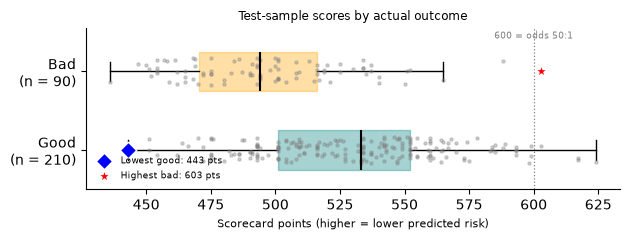

In [20]:
sc = pd.DataFrame({"score": score_card, "bad": y_test, "p_bad": p_te}, index=test.index)

bad_hi = sc[sc["bad"] == 1]["score"].idxmax()
good_lo = sc[sc["bad"] == 0]["score"].idxmin()

n_bad_ties = (sc[sc["bad"] == 1]["score"] == sc.loc[bad_hi, "score"]).sum()
n_good_ties = (sc[sc["bad"] == 0]["score"] == sc.loc[good_lo, "score"]).sum()

print(f"Highest-scoring bad : index {bad_hi}, score {sc.loc[bad_hi,'score']:.0f}, P(bad) {sc.loc[bad_hi,'p_bad']:.1%} (ties: {n_bad_ties})")
print(f"Lowest-scoring good : index {good_lo}, score {sc.loc[good_lo,'score']:.0f}, P(bad) {sc.loc[good_lo,'p_bad']:.1%} (ties: {n_good_ties})")

display(data.loc[[bad_hi, good_lo], final_vars + ["bad"]])
fig, ax = plt.subplots(figsize=(6.4, 2.5))
gd, bd = sc[sc["bad"] == 0]["score"], sc[sc["bad"] == 1]["score"]

bp = ax.boxplot([gd, bd], vert=False, widths=0.5, patch_artist=True, showfliers=False)

for patch, color in zip(bp["boxes"], ['teal', 'orange']):  patch.set(facecolor=color, alpha=0.35, edgecolor=color)
for median in bp["medians"]:  median.set(color='black', lw=1.5)

rng = np.random.default_rng(SEED)
for pos, s_vals in enumerate([gd, bd], start=1): 
    ax.scatter(s_vals, pos + rng.uniform(-0.17, 0.17, len(s_vals)), s=5, color='grey', alpha=0.35, zorder=2)

ax.scatter(sc.loc[good_lo, "score"], 1, s=70, marker="D", color="blue", zorder=5, edgecolor="white", label=f"Lowest good: {sc.loc[good_lo,'score']:.0f} pts")
ax.scatter(sc.loc[bad_hi, "score"], 2, s=90, marker="*", color="red", zorder=5, edgecolor="white", label=f"Highest bad: {sc.loc[bad_hi,'score']:.0f} pts")

ax.axvline(600, color='grey', linestyle=":", linewidth=0.9)
ax.text(600, 2.42, "600 = odds 50:1", fontsize=6.5, color='grey', ha="center")

ax.set_yticks([1, 2])
ax.set_yticklabels([f"Good\n(n = {len(gd)})", f"Bad\n(n = {len(bd)})"])
ax.set_ylim(0.5, 2.55)
ax.set_xlabel("Scorecard points (higher = lower predicted risk)", fontsize=8)
ax.set_title("Test-sample scores by actual outcome", fontsize=8.5)
ax.legend(loc="lower left", fontsize=6.8, frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

Categories

In [21]:
cat_labels = {
    "status": {1: "balance < 0 DM", 2: "0–200 DM", 3: "≥ 200 DM / salary", 4: "no checking account"},
    "credit_history": {0: "past payment delays", 1: "critical / credits elsewhere", 2: "no credits / all repaid", 3: "existing credits paid duly", 4: "all credits here repaid"},
    "purpose": {0: "other", 1: "new car", 2: "used car", 3: "furniture/equipment", 4: "radio/TV", 5: "domestic appliances", 6: "repairs", 7: "education", 8: "vacation", 9: "retraining", 10: "business"},
    "savings": {1: "unknown / none", 2: "< 100 DM", 3: "100–500 DM", 4: "500–1,000 DM", 5: "≥ 1,000 DM"},
    "employment_duration": {1: "unemployed", 2: "< 1 year", 3: "1–4 years", 4: "4–7 years", 5: "≥ 7 years"},
    "installment_rate": {1: "≥ 35% of income", 2: "25–35%", 3: "20–25%", 4: "< 20%"},
    "personal_status_sex": {1: "male, divorced/separated", 2: "female non-single / male single", 3: "male, married/widowed", 4: "female, single"},
    "other_debtors": {1: "none", 2: "co-applicant", 3: "guarantor"},
    "present_residence": {1: "< 1 year", 2: "1–4 years", 3: "4–7 years", 4: "≥ 7 years"},
    "property": {1: "unknown / none", 2: "car or other", 3: "savings agr. / life insurance", 4: "real estate"},
    "other_installment_plans": {1: "bank", 2: "stores", 3: "none"},
    "housing": {1: "free", 2: "rent", 3: "own"},
    "number_credits": {1: "1", 2: "2–3", 3: "4–5", 4: "≥ 6"},
    "job": {1: "unemployed / unskilled non-res.", 2: "unskilled resident", 3: "skilled employee", 4: "manager / self-employed"},
    "people_liable": {1: "3 or more", 2: "0 to 2"},
    "telephone": {1: "no", 2: "yes"},
    "foreign_worker": {1: "yes", 2: "no"}
}

num = ["duration", "amount", "age"]
cat = list(cat_labels)
var = num + cat
units = {"duration": "months", "age": "years", "amount": ""}
readable = {
    "status": "checking account", "credit_history": "credit history", "employment_duration": "employment duration",
    "installment_rate": "instalment rate", "personal_status_sex": "personal status/sex", "other_debtors": "other debtors",
    "present_residence": "residence duration", "other_installment_plans": "other instalment plans", "number_credits": "number of credits",
    "people_liable": "dependants", "foreign_worker": "foreign worker", "duration": "credit duration", "amount": "credit amount"
}
nice = lambda v: readable.get(v, v.replace("_", " "))
ordinal = {"employment_duration", "installment_rate", "present_residence", "number_credits", "job"}    
exclude = {"personal_status_sex": "contains sex", "foreign_worker": "nationality"}

n_dup, n_missing = int(credit.duplicated().sum()), int(credit.isna().sum().sum())
print(f"Dimensions: {credit.shape[0]} rows x {credit.shape[1]} columns (20 predictors + credit_risk (target column))")
print("Variable types:", credit.dtypes.astype(str).value_counts().to_dict(), "-> all numeric; 17 categorical variables are category codes")
print("Missing values:", n_missing, "| duplicate rows:", n_dup)
print("credit_risk counts (0 = bad, 1 = good):", credit["credit_risk"].value_counts().sort_index().to_dict())
display(credit[num].describe().T[["min", "25%", "50%", "75%", "max"]])

# modelling target: 1 = bad, 0 = good 
data = credit.copy()
data["bad"] = 1 - data["credit_risk"]

# reproducible stratified 70/30 split 
train, test = train_test_split(data, test_size=0.30, random_state=SEED, stratify=data["bad"])
print(f"\nSplit with random_state={SEED}: train {len(train)} rows ({train['bad'].sum()} bad, {train['bad'].mean():.1%}), "f"test {len(test)} rows ({test['bad'].sum()} bad, {test['bad'].mean():.1%})")

Dimensions: 1000 rows x 21 columns (20 predictors + credit_risk (target column))
Variable types: {'int64': 21} -> all numeric; 17 categorical variables are category codes
Missing values: 0 | duplicate rows: 0
credit_risk counts (0 = bad, 1 = good): {0: 300, 1: 700}


,min,25%,50%,75%,max
duration,4.0,12.0,18.0,24.00,72.0
amount,250.0,1365.5,2319.5,3972.25,18424.0
age,19.0,27.0,33.0,42.00,75.0



Split with random_state=2026: train 700 rows (210 bad, 30.0%), test 300 rows (90 bad, 30.0%)


In [22]:
def woe_table(levels, y, smooth=0.5):
    d = pd.DataFrame({"level": pd.Categorical(levels), "bad": np.asarray(y, dtype=int)})
    g = d.groupby("level", observed=False)["bad"].agg(n="size", bad="sum")
    g["good"] = g["n"] - g["bad"]
    k, G, B = len(g), g["good"].sum(), g["bad"].sum()
    g["dist_good"] = (g["good"] + smooth) / (G + smooth * k)
    g["dist_bad"] = (g["bad"] + smooth) / (B + smooth * k)
    g["woe"] = np.log(g["dist_good"] / g["dist_bad"])
    g["iv_part"] = (g["dist_good"] - g["dist_bad"]) * g["woe"]
    g["bad_rate"] = g["bad"] / g["n"].replace(0, np.nan)
    return g

def iv_strength(iv):
    return "not useful" if iv < 0.02 else "weak" if iv < 0.1 else "medium" if iv < 0.3 else "strong" if iv < 0.5 else "very strong"

def wilson(k, n, z=1.96):
    p = k/n
    d = 1+z*z/n
    c = p+z*z/(2*n)
    a = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))
    return (c-a)/d,(c+a)/d

def quant_labels(var, edges, integer):
    u = f" {units[var]}" if units.get(var) else ""
    f = (lambda v: f"{v:,.0f}") if integer else (lambda v: f"{v:,.2f}")
    e = list(edges)
    if not e: 
        return ["all"]
    labs = [f"≤ {f(e[0])}{u}"]
    for a, b in zip(e[:-1], e[1:]):
        labs.append(f"{f(a + 1)}–{f(b)}{u}" if integer else f"({f(a)}, {f(b)}]{u}")
    return labs + [f"> {f(e[-1])}{u}"]

def auto_edges(x, y, max_bins=4, min_frac=0.05, start=10, monotone=True):
    x = np.asarray(x, float)
    y = np.asarray(y)
    cand = np.unique(np.quantile(x, np.linspace(0, 1, start + 1)[1:-1]))
    if np.allclose(x, np.round(x)): cand = np.unique(np.floor(cand))
    edges = np.array([e for e in cand if x.min() < e < x.max()])
    
    tab = lambda e: (lambda t: (t["n"].to_numpy(), t["woe"].to_numpy()))(woe_table(pd.cut(x, [-np.inf, *e, np.inf]), y))
    
    if monotone and len(edges) > 1:
        w0 = tab(edges)[1]
        up = np.corrcoef(np.arange(len(w0)), w0)[0, 1] >= 0
        while len(edges) > 1:
            w = tab(edges)[1]
            viol = np.where((np.diff(w) if up else -np.diff(w)) < 0)[0]
            if len(viol) == 0: break
            edges = np.delete(edges, viol[0])
            
    while len(edges) > 1:
        n, w = tab(edges)
        small = (n / len(x)).min() < min_frac
        if len(n) <= max_bins and not small: break
        if small:
            s_ = int(n.argmin())
            cands = [j for j in (s_ - 1, s_) if 0 <= j < len(edges)]
            drop = min(cands, key=lambda j: abs(w[j] - w[j + 1]))
        else: drop = int(np.argmin(np.abs(np.diff(w))))
        edges = np.delete(edges, drop)
        
    return [float(e) for e in edges]

def group_label(var, codes):
    names = [cat_labels[var][c] for c in sorted(codes)]
    return " + ".join(names) if len(names) <= 2 else f"{names[0]} + {names[1]} + {len(names) - 2} more"

def merge_levels(x, y, var, ordinal, min_frac, manual=None):
    if manual:
        mp = {c: name for name, cs in manual.items() for c in cs}
        return {c: mp.get(c, cat_labels[var][c]) for c in sorted(x.unique())}
    groups = [[c] for c in sorted(x.unique())]
    while len(groups) > 2:
        st = [(int(x.isin(g).sum()), int(y[x.isin(g)].sum())) for g in groups]
        ns = np.array([s[0] for s in st])
        if ns.min() / len(x) >= min_frac: 
            break
        G, B, k = sum(n - b for n, b in st), sum(b for n, b in st), len(groups)
        woe = np.array([np.log(((n - b + .5) / (G + .5 * k)) / ((b + .5) / (B + .5 * k))) for n, b in st])
        s = int(ns.argmin())
        cands = [j for j in (s - 1, s + 1) if 0 <= j < len(groups)] if ordinal else [j for j in range(len(groups)) if j != s]
        j = min(cands, key=lambda j: abs(woe[s] - woe[j]))
        lo, hi = sorted((s, j))
        groups[lo] = groups[lo] + groups[hi]
        del groups[hi]
    return {c: group_label(var, g) for g in groups for c in g}


def get_bin_levels(x, kind, edges, order, cat_map, neutral):
    x_ser = pd.Series(np.asarray(x))
    if kind == "quant": return pd.Categorical(pd.cut(x_ser, [-np.inf, *edges, np.inf], labels=order))
    else:
        lab = x_ser.map(cat_map)
        if lab.isna().sum() > 0 and neutral is not None: lab = lab.fillna(neutral)
        return pd.Categorical(lab, categories=order)

def fit_binner(var, x, y, max_bins=4, min_frac=0.05, manual=None, monotone=True):
    x_s, y_s = pd.Series(np.asarray(x)), pd.Series(np.asarray(y))
    kind = "quant" if var in num else "cat"
    
    if kind == "quant":
        integer = bool(np.allclose(x_s, np.round(x_s)))
        edges = list(manual) if manual is not None else auto_edges(x_s, y_s, max_bins, min_frac, monotone=monotone)
        order = quant_labels(var, edges, integer)
        cat_map, neutral = None, None
        lvls = get_bin_levels(x_s, kind, edges, order, cat_map, neutral)
    else:
        cat_map = merge_levels(x_s, y_s, var, var in ordinal, min_frac, manual)
        order = list(dict.fromkeys(cat_map[c] for c in sorted(cat_map)))
        edges = None
        temp_lab = x_s.map(cat_map)
        temp_neutral = temp_lab.dropna().iloc[0] if len(temp_lab.dropna()) > 0 else "unknown"
        lvls = pd.Categorical(temp_lab.fillna(temp_neutral), categories=order)

    table = woe_table(lvls, y_s)
    woe_map = table["woe"].to_dict()
    iv = float(table["iv_part"].sum())
    neutral = min(woe_map, key=lambda l: abs(woe_map[l]))

    if kind == "cat":
        lvls = get_bin_levels(x_s, kind, edges, order, cat_map, neutral)
        table = woe_table(lvls, y_s)
        woe_map = table["woe"].to_dict()
        iv = float(table["iv_part"].sum())
        neutral = min(woe_map, key=lambda l: abs(woe_map[l]))

    return {
        "var": var, "kind": kind, "edges": edges, "order": order,
        "map": cat_map, "neutral": neutral, "table": table, 
        "woe_map": woe_map, "iv": iv
    }

def transform_woe(x, model):
    x_ser = pd.Series(np.asarray(x))
    lvls = get_bin_levels(x_ser, model["kind"], model["edges"], model["order"], model["map"], model["neutral"])
    idx = x.index if hasattr(x, "index") else None
    return pd.Series(pd.Series(lvls).map(model["woe_map"]).astype(float).to_numpy(), index=idx)

make_binner = lambda v, **kw: fit_binner(v, train[v], train["bad"], **kw) # Note: typically called dynamically in loops

rows = []
for v in var:
    model = fit_binner(v, train[v], train["bad"])
    rows.append({
        "Predictor": v, 
        "Type": "Quantitative" if v in num else "Categorical", 
        "Levels": len(model["order"]),
        "IV": model["iv"], 
        "Strength": iv_strength(model["iv"]), 
        "Excluded": exclude.get(v, "")
    })

screen = pd.DataFrame(rows).sort_values("IV", ascending=False).reset_index(drop=True)
display(screen.style.format({"IV": "{:.3f}"}).background_gradient(subset=["IV"], cmap="Blues").hide(axis="index"))


Predictor,Type,Levels,IV,Strength,Excluded
status,Categorical,4,0.559,very strong,
savings,Categorical,5,0.300,strong,
duration,Quantitative,4,0.298,medium,
purpose,Categorical,6,0.238,medium,
credit_history,Categorical,4,0.233,medium,
property,Categorical,4,0.101,medium,
amount,Quantitative,4,0.100,medium,
age,Quantitative,4,0.098,weak,
employment_duration,Categorical,5,0.092,weak,
housing,Categorical,3,0.072,weak,


In [23]:
usable = screen[screen["Excluded"] == ""]
cat_var = usable[usable["Type"] == "Categorical"]["Predictor"].iloc[0]
q_var = usable[usable["Type"] == "Quantitative"]["Predictor"].iloc[0]

iv_of = lambda v: float(screen.loc[screen["Predictor"] == v, "IV"].iloc[0])
print(f"Chosen: {cat_var} (IV {iv_of(cat_var):.2f}) and {q_var} (IV {iv_of(q_var):.2f})")

bc_model = fit_binner(cat_var, train[cat_var], train["bad"], min_frac=0.10)
bq_model = fit_binner(q_var, train[q_var], train["bad"], max_bins=3, min_frac=0.15)

def get_levels(x, model):
    x_s = pd.Series(np.asarray(x))
    if model["kind"] == "quant":
        return pd.Categorical(pd.cut(x_s, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    return pd.Categorical(x_s.map(model["map"]).fillna(model["neutral"]), categories=model["order"])

def joint_table(cat_levels, q_levels, y):
    d = pd.DataFrame({"cat": cat_levels, "q": q_levels, "bad": np.asarray(y)})
    g = d.groupby(["cat", "q"], observed=True)["bad"].agg(n="size", bad="sum")
    g["rate"] = g["bad"] / g["n"]
    ci = np.array([wilson(k, n) for k, n in zip(g["bad"], g["n"])])
    g["lo"], g["hi"] = ci[:, 0], ci[:, 1]
    return g

g = joint_table(get_levels(train[cat_var], bc_model), get_levels(train[q_var], bq_model), train["bad"])
overall, B_train = float(train["bad"].mean()), int(train["bad"].sum())

show = g.copy()
show["share of all bad"] = show["bad"] / B_train
display(show.style.format("{:.1%}", subset=["rate", "lo", "hi", "share of all bad"]) if hasattr(show.style, "format") else show)

top_rate, top_count = g["rate"].idxmax(), g["bad"].idxmax()
reliable = g[g["n"] >= 30]
print(f"\nHighest rate: {top_rate} (Rate: {g.loc[top_rate,'rate']:.1%}, n={g.loc[top_rate,'n']}, 95% CI: {g.loc[top_rate,'lo']:.1%}-{g.loc[top_rate,'hi']:.1%})")
print(f"Most bad credits: {top_count} ({g.loc[top_count,'bad']} of {B_train} bad, Rate: {g.loc[top_count,'rate']:.1%})")

alt_edges = list(np.unique(np.floor(train[q_var].quantile([1 / 3, 2 / 3]).to_numpy())))
bq2_model = fit_binner(q_var, train[q_var], train["bad"], manual=alt_edges)
bc2_model = fit_binner(cat_var, train[cat_var], train["bad"], min_frac=0.05)
g2 = joint_table(get_levels(train[cat_var], bc2_model), get_levels(train[q_var], bq2_model), train["bad"])

print(f"Alternative grouping highest rate: {g2['rate'].idxmax()} ({g2['rate'].max():.1%}, n={g2.loc[g2['rate'].idxmax(),'n']})")

Chosen: status (IV 0.56) and duration (IV 0.30)



Highest rate: ('balance < 0 DM', '> 24 months') (Rate: 66.7%, n=45, 95% CI: 52.1%-78.6%)
Most bad credits: ('balance < 0 DM', '16–24 months') (35 of 210 bad, Rate: 52.2%)
Alternative grouping highest rate: ('balance < 0 DM', '> 24 months') (66.7%, n=45)


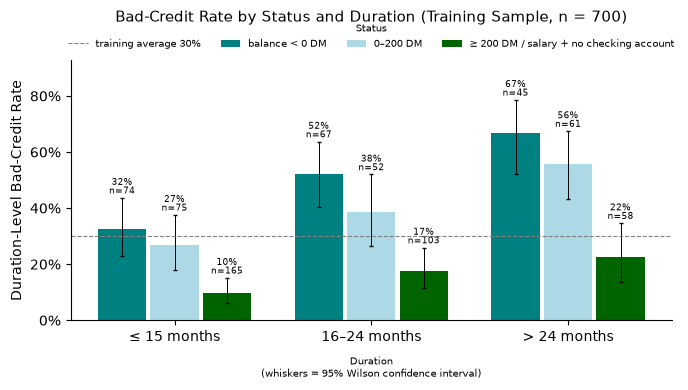

In [24]:
def plot_joint(g, cat_order, q_order, cat_name, q_name, overall, n_train, figsize=(7.2, 4.0)):
    clean_cat_name = cat_name.strip().title()
    clean_q_name = q_name.strip().title()

    colors = ["teal", "lightblue", "darkgreen", "orange"]
    fig, ax = plt.subplots(figsize=figsize)
    
    nc = len(cat_order)
    bar_width = 0.8 / nc  
    for i, cat in enumerate(cat_order):
        for j, q in enumerate(q_order):
            if (cat, q) not in g.index:
                continue
            
            row = g.loc[(cat, q)]
            x_pos = j + (i - (nc - 1) / 2) * bar_width
            ax.bar(x_pos, row["rate"], width=bar_width * 0.92, color=colors[i % len(colors)], linewidth=0.5, label=cat if j == 0 else "")
            ax.errorbar(x_pos, row["rate"],  yerr=[[row["rate"] - row["lo"]], [row["hi"] - row["rate"]]], color="black", lw=0.7, capsize=1.5)
            ax.text(x_pos, row["hi"] + 0.012, f"{row['rate']:.0%}\nn={int(row['n'])}", ha="center", va="bottom", fontsize=6.5, linespacing=0.95)

    ax.axhline(overall, color="gray", linestyle="--", linewidth=0.8, label=f"training average {overall:.0%}")
    ax.set_xticks(range(len(q_order)))
    ax.set_xticklabels([str(q) for q in q_order], fontsize=10)
    
    ax.set_ylim(0, min(1.0, g["hi"].max() + 0.14)) # Add padding for labels
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylabel(f"{clean_q_name}-Level Bad-Credit Rate", fontsize=10)
    
    ax.set_xlabel(f"{clean_q_name}\n(whiskers = 95% Wilson confidence interval)", fontsize=7, labelpad=8)
    ax.set_title(f"Bad-Credit Rate by {clean_cat_name} and {clean_q_name} (Training Sample, n = {n_train})", fontsize=11, fontweight="normal", pad=28)
    ax.legend(title=f"{clean_cat_name}", ncol=min(nc + 1, 4), fontsize=7, title_fontsize=7.5, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.01))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    
    return fig

overall_rate = float(train["bad"].mean())
fig1 = plot_joint(g=g, cat_order=bc_model["order"], q_order=bq_model["order"], cat_name=cat_var, q_name=q_var, overall=overall_rate, n_train=len(train))
plt.show()

In [25]:
data.groupby("status")["bad"].agg(n="size", bad_rate="mean")

,n,bad_rate
status,,
1,274,0.492701
2,269,0.390335
3,63,0.222222
4,394,0.116751


k,cv_auc,sd,se
1,0.693,0.035,0.015
2,0.733,0.037,0.016
3,0.759,0.035,0.016
4,0.761,0.036,0.016
5,0.779,0.036,0.016
6,0.768,0.047,0.021
7,0.770,0.049,0.022
8,0.767,0.046,0.021
9,0.770,0.043,0.019
10,0.775,0.037,0.017


Best CV AUC: 0.779 at k=5 (SE: 0.016)
Optimal k within tolerance: 5
Selected predictors: ['status', 'savings', 'duration', 'purpose', 'credit_history']


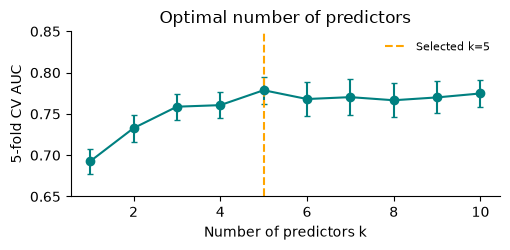

 • Smallest IV: 0.233
 • Strongest predictor association: duration & purpose (Cramer's V = 0.17)


In [27]:
def fit_lr(X, y):
    return LogisticRegression(C=np.inf, solver="lbfgs", max_iter=10000, tol=1e-10).fit(X, y)

CAND = [v for v in var if v not in exclude]
K_MAX, TOL, K_CAP = 10, 0.005, 8  
FINAL_OVERRIDE = None         

def transform_woe(x, model):
    x_ser = pd.Series(np.asarray(x))
    if model["kind"] == "quant": lvls = pd.Categorical(pd.cut(x_ser, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    else: lvls = pd.Categorical(x_ser.map(model["map"]).fillna(model["neutral"]), categories=model["order"])
    idx = x.index if hasattr(x, "index") else None
    return pd.Series(pd.Series(lvls).map(model["woe_map"]).astype(float).to_numpy(), index=idx)

def run_cv_k_curve(df, cand, k_max, n_splits=5, seed=SEED):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = {k: [] for k in range(1, k_max + 1)}
    
    for train_idx, val_idx in skf.split(df, df["bad"]):
        train_fold, val_fold = df.iloc[train_idx], df.iloc[val_idx]
        
        fold_fits = {v: fit_binner(v, train_fold[v], train_fold["bad"]) for v in cand}
        iv_ranked_vars = sorted(cand, key=lambda v: fold_fits[v]["iv"], reverse=True)
        
        xtrain_woe = pd.DataFrame({v: transform_woe(train_fold[v], fold_fits[v]) for v in cand})
        xval_woe = pd.DataFrame({v: transform_woe(val_fold[v], fold_fits[v]) for v in cand})
        
        for k in scores:
            selected_cols = iv_ranked_vars[:k]
            lr_model = fit_lr(xtrain_woe[selected_cols], train_fold["bad"])
            preds = lr_model.predict_proba(xval_woe[selected_cols])[:, 1]
            scores[k].append(roc_auc_score(val_fold["bad"], preds))
            
    cv_summary = pd.DataFrame({
        "k": list(scores),
        "cv_auc": [np.mean(vals) for vals in scores.values()],
        "sd": [np.std(vals, ddof=1) for vals in scores.values()]
    })
    cv_summary["se"] = cv_summary["sd"] / np.sqrt(n_splits)
    return cv_summary

cvk = run_cv_k_curve(train, CAND, K_MAX)

best_row = cvk.loc[cvk["cv_auc"].idxmax()]
k_star = int(cvk[cvk["cv_auc"] >= best_row["cv_auc"] - TOL]["k"].min())
k_1se = int(cvk[cvk["cv_auc"] >= best_row["cv_auc"] - best_row["se"]]["k"].min())
k_uncapped = k_star
k_star = min(k_star, K_CAP)

iv_rank = [v for v in screen["Predictor"] if v in CAND]
final_vars = list(FINAL_OVERRIDE) if FINAL_OVERRIDE else iv_rank[:k_star]

if not any(v in num for v in final_vars):
    first_quant = next(v for v in iv_rank if v in num)
    final_vars[-1] = first_quant

display(cvk.style.format({"cv_auc": "{:.3f}", "sd": "{:.3f}", "se": "{:.3f}"}).hide(axis="index") if hasattr(cvk.style, "hide") else cvk)

print(f"Best CV AUC: {best_row['cv_auc']:.3f} at k={int(best_row['k'])} (SE: {best_row['se']:.3f})")
print(f"Optimal k within tolerance: {k_uncapped}")
print("Selected predictors:", final_vars)

fig, ax = plt.subplots(figsize=(5.2, 2.6))
ax.errorbar(cvk["k"], cvk["cv_auc"], yerr=cvk["se"], marker="o", color='teal', capsize=2)
ax.axvline(k_star, color='orange', linestyle="--", label=f"Selected k={k_star}")
ax.set_ylim(0.65, 0.85)
ax.set_xlabel("Number of predictors k")
ax.set_ylabel("5-fold CV AUC")
ax.set_title("Optimal number of predictors")
ax.legend(frameon=False, fontsize=8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


fits_sel = {v: fit_binner(v, train[v], train["bad"]) for v in final_vars}
def cramers_v(a, b):
    ct = pd.crosstab(np.asarray(a), np.asarray(b))
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))) if min(ct.shape) > 1 else 0.0
    
def get_bin_levels_eval(x, model):
    x_ser = pd.Series(np.asarray(x))
    if model["kind"] == "quant": return pd.Categorical(pd.cut(x_ser, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    return pd.Categorical(x_ser.map(model["map"]).fillna(model["neutral"]), categories=model["order"])

pairs = [
    (a, b, cramers_v(get_bin_levels_eval(train[a], fits_sel[a]), get_bin_levels_eval(train[b], fits_sel[b])))
    for i, a in enumerate(final_vars)
    for b in final_vars[i + 1:]
]
max_pair = max(pairs, key=lambda t: t[2])
min_iv = min(f["iv"] for f in fits_sel.values())

print(f" • Smallest IV: {min_iv:.3f}")
print(f" • Strongest predictor association: {max_pair[0]} & {max_pair[1]} (Cramer's V = {max_pair[2]:.2f})")

In [28]:
models = {v: fit_binner(v, train[v], train["bad"]) for v in final_vars}

parts = []
for v in final_vars:
    t = models[v]["table"].reset_index()
    t.insert(0, "predictor", v)
    parts.append(t[["predictor", "level", "n", "bad", "bad_rate", "woe", "iv_part"]])

woe_tab = pd.concat(parts, ignore_index=True)
woe_tab["share"] = woe_tab["n"] / len(train)

display(woe_tab.style.format({"bad_rate": "{:.1%}", "woe": "{:+.3f}", "iv_part": "{:.4f}", "share": "{:.1%}"}).hide(axis="index") if hasattr(woe_tab.style, "hide") else woe_tab)

iv_rows = []
for v in final_vars:
    iv_val = models[v]["iv"]
    iv_rows.append({
        "predictor": v,
        "IV": iv_val,
        "levels": len(models[v]["order"]),
        "strength": iv_strength(iv_val)
    })

iv_tab = pd.DataFrame(iv_rows).sort_values("IV", ascending=False).reset_index(drop=True)

display(iv_tab.style.format({"IV": "{:.3f}"}).hide(axis="index") if hasattr(iv_tab.style, "hide") else iv_tab)

top_iv_var = iv_tab.loc[0, "predictor"]
top_iv_val = iv_tab.loc[0, "IV"]
top_strength = iv_tab.loc[0, "strength"]

print(f"Highest training IV: {top_iv_var} (IV = {top_iv_val:.3f}, {top_strength})")
print("WOE by level of the highest-IV predictor:")
display(models[top_iv_var]["table"][["n", "bad_rate", "woe"]].sort_values("woe", ascending=False))

for v in final_vars:
    m = models[v]
    if m["kind"] == "cat":
        merged = [lvl for lvl in m["order"] if " + " in lvl]
        if merged: 
            print(f"Merged levels in {v}: {merged}")

predictor,level,n,bad,bad_rate,woe,iv_part,share
status,balance < 0 DM,186,89,47.8%,-0.756,0.1694,26.6%
status,0–200 DM,188,74,39.4%,-0.412,0.0489,26.9%
status,≥ 200 DM / salary,50,11,22.0%,+0.392,0.0102,7.1%
status,no checking account,276,36,13.0%,+1.044,0.3304,39.4%
savings,unknown / none,416,157,37.7%,-0.341,0.0731,59.4%
savings,< 100 DM,78,25,32.1%,-0.100,0.0011,11.1%
savings,100–500 DM,40,6,15.0%,+0.829,0.0327,5.7%
savings,"500–1,000 DM",35,3,8.6%,+1.388,0.0687,5.0%
savings,"≥ 1,000 DM",131,19,14.5%,+0.912,0.1246,18.7%
duration,≤ 9 months,99,14,14.1%,+0.932,0.0983,14.1%


predictor,IV,levels,strength
status,0.559,4,very strong
savings,0.300,5,strong
duration,0.298,4,medium
purpose,0.238,6,medium
credit_history,0.233,4,medium


Highest training IV: status (IV = 0.559, very strong)
WOE by level of the highest-IV predictor:


,n,bad_rate,woe
level,,,
no checking account,276,0.130435,1.043515
≥ 200 DM / salary,50,0.220000,0.392061
0–200 DM,188,0.393617,-0.412117
balance < 0 DM,186,0.478495,-0.756279


Merged levels in purpose: ['furniture/equipment + vacation', 'radio/TV + domestic appliances + 2 more']
Merged levels in credit_history: ['past payment delays + critical / credits elsewhere']


In [29]:
models = {v: fit_binner(v, train[v], train["bad"]) for v in final_vars}

parts = []
for v in final_vars:
    t = models[v]["table"].reset_index()
    t.insert(0, "predictor", v)
    parts.append(t[["predictor", "level", "n", "bad", "bad_rate", "woe", "iv_part"]])

woe_tab = pd.concat(parts, ignore_index=True)
woe_tab["share"] = woe_tab["n"] / len(train)

display(woe_tab.style.format({"bad_rate": "{:.1%}", "woe": "{:+.3f}", "iv_part": "{:.4f}", "share": "{:.1%}"}).hide(axis="index") if hasattr(woe_tab.style, "hide") else woe_tab)

iv_rows = []
for v in final_vars:
    iv_val = models[v]["iv"]
    iv_rows.append({
        "predictor": v,
        "IV": iv_val,
        "levels": len(models[v]["order"]),
        "strength": iv_strength(iv_val)
    })

iv_tab = pd.DataFrame(iv_rows).sort_values("IV", ascending=False).reset_index(drop=True)

display(iv_tab.style.format({"IV": "{:.3f}"}).hide(axis="index") if hasattr(iv_tab.style, "hide") else iv_tab)

top_iv_var = iv_tab.loc[0, "predictor"]
top_iv_val = iv_tab.loc[0, "IV"]
top_strength = iv_tab.loc[0, "strength"]

print(f"Highest training IV: {top_iv_var} (IV = {top_iv_val:.3f}, {top_strength})")
print("WOE by level of the highest-IV predictor:")
display(models[top_iv_var]["table"][["n", "bad_rate", "woe"]].sort_values("woe", ascending=False))

for v in final_vars:
    m = models[v]
    if m["kind"] == "cat":
        merged = [lvl for lvl in m["order"] if " + " in lvl]
        if merged: 
            print(f"Merged levels in {v}: {merged}")

predictor,level,n,bad,bad_rate,woe,iv_part,share
status,balance < 0 DM,186,89,47.8%,-0.756,0.1694,26.6%
status,0–200 DM,188,74,39.4%,-0.412,0.0489,26.9%
status,≥ 200 DM / salary,50,11,22.0%,+0.392,0.0102,7.1%
status,no checking account,276,36,13.0%,+1.044,0.3304,39.4%
savings,unknown / none,416,157,37.7%,-0.341,0.0731,59.4%
savings,< 100 DM,78,25,32.1%,-0.100,0.0011,11.1%
savings,100–500 DM,40,6,15.0%,+0.829,0.0327,5.7%
savings,"500–1,000 DM",35,3,8.6%,+1.388,0.0687,5.0%
savings,"≥ 1,000 DM",131,19,14.5%,+0.912,0.1246,18.7%
duration,≤ 9 months,99,14,14.1%,+0.932,0.0983,14.1%


predictor,IV,levels,strength
status,0.559,4,very strong
savings,0.300,5,strong
duration,0.298,4,medium
purpose,0.238,6,medium
credit_history,0.233,4,medium


Highest training IV: status (IV = 0.559, very strong)
WOE by level of the highest-IV predictor:


,n,bad_rate,woe
level,,,
no checking account,276,0.130435,1.043515
≥ 200 DM / salary,50,0.220000,0.392061
0–200 DM,188,0.393617,-0.412117
balance < 0 DM,186,0.478495,-0.756279


Merged levels in purpose: ['furniture/equipment + vacation', 'radio/TV + domestic appliances + 2 more']
Merged levels in credit_history: ['past payment delays + critical / credits elsewhere']


In [30]:
binners = {v: fit_binner(v, train[v], train["bad"]) for v in final_vars}

def transform_woe(x, model):
    x_ser = pd.Series(np.asarray(x))
    if model["kind"] == "quant": lvls = pd.Categorical(pd.cut(x_ser, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    else: lvls = pd.Categorical(x_ser.map(model["map"]).fillna(model["neutral"]), categories=model["order"])
    idx = x.index if hasattr(x, "index") else None
    return pd.Series(pd.Series(lvls).map(model["woe_map"]).astype(float).to_numpy(), index=idx)

X_train = pd.DataFrame({v: transform_woe(train[v], binners[v]) for v in final_vars})
y_train = train["bad"].to_numpy()

logit = fit_lr(X_train, y_train)
b0 = float(logit.intercept_[0])
coefs = pd.Series(logit.coef_[0], index=final_vars)

X_design = np.column_stack([np.ones(len(X_train)), X_train.to_numpy()])
p_fit = logit.predict_proba(X_train)[:, 1]

weights = p_fit * (1 - p_fit)
fisher_info = X_design.T @ (X_design * weights[:, None])
cov_matrix = np.linalg.inv(fisher_info)
standard_errors = np.sqrt(np.diag(cov_matrix))

estimates = np.r_[b0, coefs.to_numpy()]
z_scores = estimates / standard_errors
p_values = 2 * (1 - stats.norm.cdf(np.abs(z_scores)))

coef_tab = pd.DataFrame({
    "term": ["intercept"] + final_vars,
    "coefficient": estimates,
    "std. error": standard_errors,
    "z": z_scores,
    "p-value": p_values
})

display(coef_tab.style.format({"coefficient": "{:+.4f}", "std. error": "{:.4f}", "z": "{:.2f}", "p-value": "{:.4f}"}).hide(axis="index") if hasattr(coef_tab.style, "hide") else coef_tab)

print(" Coefficients are NEGATIVE because WoE = ln(good/bad) is higher for safer levels.")
print(f" • Model Intercept: {b0:.4f}")

term,coefficient,std. error,z,p-value
intercept,-0.8477,0.0975,-8.69,0.0000
status,-0.7718,0.1313,-5.88,0.0000
savings,-0.9158,0.1934,-4.73,0.0000
duration,-0.9921,0.1765,-5.62,0.0000
purpose,-0.8979,0.1989,-4.52,0.0000
credit_history,-0.7710,0.2016,-3.82,0.0001


 Coefficients are NEGATIVE because WoE = ln(good/bad) is higher for safer levels.
 • Model Intercept: -0.8477


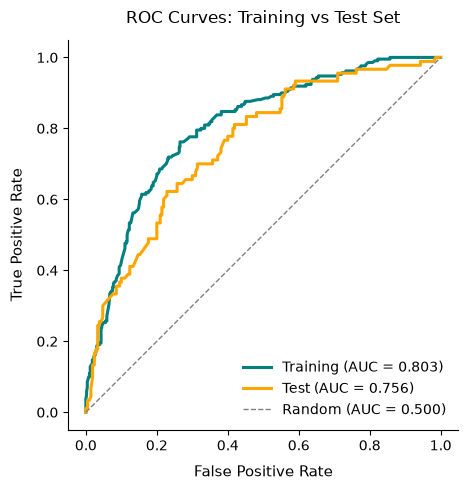

 • Train AUC: 0.803 | Test AUC: 0.756 (Bootstrap 95% CI: [0.697, 0.813])
 • Train-Test Gap: +0.048 | 5-fold CV Training AUC: 0.779
 • Gini Coefficients -> Train: 0.606, Test: 0.511
 • Test Sample Bads: 90 total
 • Bad rate in riskiest 30%: 53.3%
 • Bad rate in remaining 70%: 20.0%


In [33]:
binners = {v: fit_binner(v, train[v], train["bad"]) for v in final_vars}

def transform_woe(x, model):
    x_ser = pd.Series(np.asarray(x))
    if model["kind"] == "quant": lvls = pd.Categorical(pd.cut(x_ser, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    else: lvls = pd.Categorical(x_ser.map(model["map"]).fillna(model["neutral"]), categories=model["order"])
    idx = x.index if hasattr(x, "index") else None
    return pd.Series(pd.Series(lvls).map(model["woe_map"]).astype(float).to_numpy(), index=idx)

X_test = pd.DataFrame({v: transform_woe(test[v], binners[v]) for v in final_vars})
y_test = test["bad"].to_numpy()

for v in final_vars:
    model = binners[v]
    if model["kind"] == "cat":
        x_ser = pd.Series(np.asarray(test[v]))
        unseen_count = (~x_ser.isin(model["map"].keys())).sum()
    else: unseen_count = 0

p_tr = logit.predict_proba(X_train)[:, 1]
p_te = logit.predict_proba(X_test)[:, 1]

auc_tr = roc_auc_score(y_train, p_tr)
auc_te = roc_auc_score(y_test, p_te)

fig, ax = plt.subplots(figsize=(6.5, 5.0))
datasets = [(y_train, p_tr, "Training", 'teal'), (y_test, p_te, "Test", 'orange')]

for y_true, p_pred, name, color in datasets:
    fpr, tpr, _ = roc_curve(y_true, p_pred)
    score = roc_auc_score(y_true, p_pred)
    ax.plot(fpr, tpr, color=color, lw=2.2, label=f"{name} (AUC = {score:.3f})")

ax.plot([0, 1], [0, 1], color='grey', linestyle="--", linewidth=1.0, label="Random (AUC = 0.500)")

ax.set_xlabel("False Positive Rate", fontsize=11, labelpad=8)
ax.set_ylabel("True Positive Rate", fontsize=11, labelpad=8)
ax.set_title("ROC Curves: Training vs Test Set", fontsize=12, pad=12)

ax.legend(loc="lower right", fontsize=10, frameon=False)
ax.tick_params(labelsize=10)
ax.set_aspect("equal", adjustable="box")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

rng = np.random.default_rng(SEED)
bootstrap_aucs = []
n_test = len(y_test)

for _ in range(2000):
    sample_indices = rng.integers(0, n_test, n_test)
    y_sample = y_test[sample_indices]
    if 0 < y_sample.sum() < len(sample_indices):
        bootstrap_aucs.append(roc_auc_score(y_sample, p_te[sample_indices]))

ci_lo, ci_hi = np.percentile(bootstrap_aucs, [2.5, 97.5])

if "cvk" in locals() and len(final_vars) in set(cvk["k"]):  cv_auc_final = float(cvk.loc[cvk["k"] == len(final_vars), "cv_auc"].iloc[0])
else:  cv_auc_final = np.nan

train_test_gap = auc_tr - auc_te
gini_train = 2 * auc_tr - 1
gini_test = 2 * auc_te - 1

risk_threshold = np.quantile(p_te, 0.70)
is_risky = p_te >= risk_threshold
bad_rate_risky = y_test[is_risky].mean()
bad_rate_safe = y_test[~is_risky].mean()

print(f" • Train AUC: {auc_tr:.3f} | Test AUC: {auc_te:.3f} (Bootstrap 95% CI: [{ci_lo:.3f}, {ci_hi:.3f}])")
print(f" • Train-Test Gap: {train_test_gap:+.3f} | 5-fold CV Training AUC: {cv_auc_final:.3f}")
print(f" • Gini Coefficients -> Train: {gini_train:.3f}, Test: {gini_test:.3f}")
print(f" • Test Sample Bads: {int(y_test.sum())} total")
print(f" • Bad rate in riskiest 30%: {bad_rate_risky:.1%}")
print(f" • Bad rate in remaining 70%: {bad_rate_safe:.1%}")

In [34]:
models = {v: fit_binner(v, train[v], train["bad"]) for v in final_vars}
coefs = pd.Series(logit.coef_[0], index=final_vars)

def nice_name(var_str):
    return var_str.replace("_", " ").title()

def get_bin_levels_eval(x, model):
    x_ser = pd.Series(np.asarray(x))
    if model["kind"] == "quant": return pd.Categorical(pd.cut(x_ser, [-np.inf, *model["edges"], np.inf], labels=model["order"]))
    return pd.Categorical(x_ser.map(model["map"]).fillna(model["neutral"]), categories=model["order"])

FACTOR = 20 / np.log(2)
OFFSET = 600 - FACTOR * np.log(50)
base = (OFFSET - FACTOR * b0) / len(final_vars)
print(f"Factor = PDO/ln2 = {FACTOR:.4f}; Offset = 600 - Factor*ln(50) = {OFFSET:.4f}")
scorecard = pd.DataFrame([
    {
        "var": v,
        "predictor": nice_name(v), 
        "level": lev, 
        "points_exact": -FACTOR * coefs[v] * models[v]["woe_map"][lev] + base,
        "points": round(-FACTOR * coefs[v] * models[v]["woe_map"][lev] + base)
    }
    for v in final_vars for lev in models[v]["order"]
])

report_sc = scorecard[["predictor", "level", "points"]]
display(report_sc.style.hide(axis="index") if hasattr(report_sc.style, "hide") else report_sc)

exact = {(r.var, r.level): r.points_exact for r in scorecard.itertuples()}
rounded = {(r.var, r.level): r.points for r in scorecard.itertuples()}
lv_te = {v: get_bin_levels_eval(test[v], models[v]) for v in final_vars}

score_exact = sum(np.array([exact[(v, l)] for l in lv_te[v]]) for v in final_vars)
score_card = sum(np.array([rounded[(v, l)] for l in lv_te[v]]) for v in final_vars)
score_model = OFFSET + FACTOR * np.log((1 - p_te) / p_te)

d_exact, d_round = score_exact - score_model, score_card - score_model

print(f"Unrounded points vs model: max |diff| = {np.abs(d_exact).max():.2e}")
print(f"Integer points vs model  : max |diff| = {np.abs(d_round).max():.1f}, mean |diff| = {np.abs(d_round).mean():.2f}")
print(f"Share of scores within ±2 points: {(np.abs(d_round) <= 2).mean():.1%}")

log_odds = np.log((1 - p_te) / p_te)
slope_m, icpt_m = np.polyfit(score_model, log_odds, 1)
slope_c, icpt_c = np.polyfit(score_card, log_odds, 1)

chk = pd.DataFrame({
    "check": ["Score at odds 50:1", "Odds (good:bad) at 600 points", "Points to double the odds", "Spearman correlation (score vs P(bad))"],
    "target": [600, 50, 20, -1],
    "model-implied score": [OFFSET + FACTOR * np.log(50), np.exp(icpt_m + slope_m * 600), np.log(2) / slope_m, stats.spearmanr(score_model, p_te)[0]],
    "scorecard (integer points)": [np.nan, np.exp(icpt_c + slope_c * 600), np.log(2) / slope_c, stats.spearmanr(score_card, p_te)[0]]
})

display(chk.style.format({"model-implied score": "{:.3f}", "scorecard (integer points)": "{:.3f}"}).hide(axis="index") if hasattr(chk.style, "hide") else chk)

print(f"\nTest Score Summary:")
print(f" • Range: Min {score_card.min()} to Max {score_card.max()} (Median: {np.median(score_card):.0f})")
print(f" • Mean Score -> Good credits: {score_card[y_test==0].mean():.1f} | Bad credits: {score_card[y_test==1].mean():.1f}")

Factor = PDO/ln2 = 28.8539; Offset = 600 - Factor*ln(50) = 487.1229


predictor,level,points
Status,balance < 0 DM,85
Status,0–200 DM,93
Status,≥ 200 DM / salary,111
Status,no checking account,126
Savings,unknown / none,93
Savings,< 100 DM,100
Savings,100–500 DM,124
Savings,"500–1,000 DM",139
Savings,"≥ 1,000 DM",126
Duration,≤ 9 months,129


Unrounded points vs model: max |diff| = 1.14e-13
Integer points vs model  : max |diff| = 1.9, mean |diff| = 0.52
Share of scores within ±2 points: 100.0%


check,target,model-implied score,scorecard (integer points)
Score at odds 50:1,600,600.000,nan
Odds (good:bad) at 600 points,50,50.000,48.467
Points to double the odds,20,20.000,20.150
Spearman correlation (score vs P(bad)),-1,-1.000,-1.000



Test Score Summary:
 • Range: Min 436 to Max 624 (Median: 516)
 • Mean Score -> Good credits: 529.3 | Bad credits: 496.4


Highest-scoring bad : index 949, score 603, P(bad) 1.8% (ties: 1)
Lowest-scoring good : index 492, score 443, P(bad) 81.9% (ties: 1)


,status,savings,duration,purpose,credit_history,bad
949,4,5,12,3,4,1
492,1,1,18,9,0,0


C:\Users\athul\AppData\Local\Temp\ipykernel_15908\289394322.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot([gd, bd], vert=False, widths=0.5, patch_artist=True, showfliers=False)


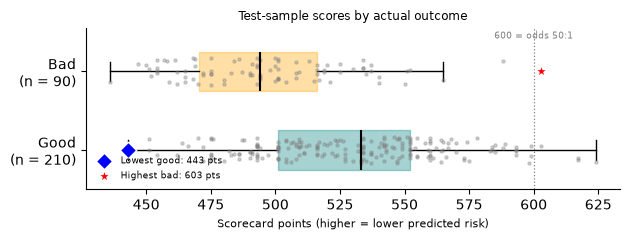

In [35]:
sc = pd.DataFrame({"score": score_card, "bad": y_test, "p_bad": p_te}, index=test.index)

bad_hi = sc[sc["bad"] == 1]["score"].idxmax()
good_lo = sc[sc["bad"] == 0]["score"].idxmin()

n_bad_ties = (sc[sc["bad"] == 1]["score"] == sc.loc[bad_hi, "score"]).sum()
n_good_ties = (sc[sc["bad"] == 0]["score"] == sc.loc[good_lo, "score"]).sum()

print(f"Highest-scoring bad : index {bad_hi}, score {sc.loc[bad_hi,'score']:.0f}, P(bad) {sc.loc[bad_hi,'p_bad']:.1%} (ties: {n_bad_ties})")
print(f"Lowest-scoring good : index {good_lo}, score {sc.loc[good_lo,'score']:.0f}, P(bad) {sc.loc[good_lo,'p_bad']:.1%} (ties: {n_good_ties})")

display(data.loc[[bad_hi, good_lo], final_vars + ["bad"]])
fig, ax = plt.subplots(figsize=(6.4, 2.5))
gd, bd = sc[sc["bad"] == 0]["score"], sc[sc["bad"] == 1]["score"]

bp = ax.boxplot([gd, bd], vert=False, widths=0.5, patch_artist=True, showfliers=False)

for patch, color in zip(bp["boxes"], ['teal', 'orange']):  patch.set(facecolor=color, alpha=0.35, edgecolor=color)
for median in bp["medians"]:  median.set(color='black', lw=1.5)

rng = np.random.default_rng(SEED)
for pos, s_vals in enumerate([gd, bd], start=1): 
    ax.scatter(s_vals, pos + rng.uniform(-0.17, 0.17, len(s_vals)), s=5, color='grey', alpha=0.35, zorder=2)

ax.scatter(sc.loc[good_lo, "score"], 1, s=70, marker="D", color="blue", zorder=5, edgecolor="white", label=f"Lowest good: {sc.loc[good_lo,'score']:.0f} pts")
ax.scatter(sc.loc[bad_hi, "score"], 2, s=90, marker="*", color="red", zorder=5, edgecolor="white", label=f"Highest bad: {sc.loc[bad_hi,'score']:.0f} pts")

ax.axvline(600, color='grey', linestyle=":", linewidth=0.9)
ax.text(600, 2.42, "600 = odds 50:1", fontsize=6.5, color='grey', ha="center")

ax.set_yticks([1, 2])
ax.set_yticklabels([f"Good\n(n = {len(gd)})", f"Bad\n(n = {len(bd)})"])
ax.set_ylim(0.5, 2.55)
ax.set_xlabel("Scorecard points (higher = lower predicted risk)", fontsize=8)
ax.set_title("Test-sample scores by actual outcome", fontsize=8.5)
ax.legend(loc="lower left", fontsize=6.8, frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()